In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
!pip install xgboost

In [ ]:
55from google.colab import files

uploaded = files.upload()

Saving US_Accidents_2022_April_September_12000.csv to US_Accidents_2022_April_September_12000 (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv(
    "US_Accidents_2022_April_September_12000.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Shape: (12000, 9)
   Severity           Start_Time  Temperature(F)  Humidity(%)  Pressure(in)  \
0         2  2022-04-08 21:06:27            54.0         67.0         29.77   
1         2  2022-09-26 00:16:23            64.0         72.0         29.58   
2         2  2022-04-06 07:19:50            49.0         61.0         29.16   
3         2  2022-07-01 14:09:30            93.0         18.0         29.07   
4         2  2022-06-06 05:40:00            63.0         87.0         29.87   

   Visibility(mi)  Wind_Speed(mph)  Precipitation(in) Weather_Condition  
0            10.0              0.0                0.0              Fair  
1            10.0             20.0                0.0     Partly Cloudy  
2            10.0              9.0                0.0            Cloudy  
3            10.0              9.0                0.0              Fair  
4            10.0              5.0                0.0     Partly Cloudy  


In [ ]:
df.head()

,Severity,Start_Time,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition
0,2,2022-04-08 21:06:27,54.0,67.0,29.77,10.0,0.0,0.0,Fair
1,2,2022-09-26 00:16:23,64.0,72.0,29.58,10.0,20.0,0.0,Partly Cloudy
2,2,2022-04-06 07:19:50,49.0,61.0,29.16,10.0,9.0,0.0,Cloudy
3,2,2022-07-01 14:09:30,93.0,18.0,29.07,10.0,9.0,0.0,Fair
4,2,2022-06-06 05:40:00,63.0,87.0,29.87,10.0,5.0,0.0,Partly Cloudy


In [ ]:
print(df.columns.tolist())

['Severity', 'Start_Time', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition']


In [ ]:
features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)',
    'Weather_Condition'
]

df_model = df[['Severity'] + features].copy()

print(df_model.shape)
df_model.head()

(12000, 8)


,Severity,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition
0,2,54.0,67.0,29.77,10.0,0.0,0.0,Fair
1,2,64.0,72.0,29.58,10.0,20.0,0.0,Partly Cloudy
2,2,49.0,61.0,29.16,10.0,9.0,0.0,Cloudy
3,2,93.0,18.0,29.07,10.0,9.0,0.0,Fair
4,2,63.0,87.0,29.87,10.0,5.0,0.0,Partly Cloudy


In [ ]:
print(df_model['Severity'].value_counts().sort_index())

Severity
1    3000
2    6000
3    2000
4    1000
Name: count, dtype: int64


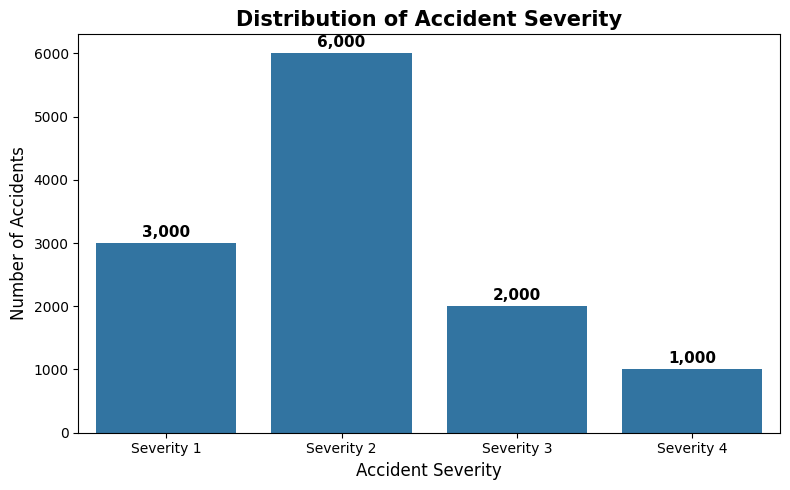

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Severity counts
severity_counts = df_model['Severity'].value_counts().sort_index()

# Create figure
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=severity_counts.index,
    y=severity_counts.values
)

# Add values on top of bars
for i, value in enumerate(severity_counts.values):
    ax.text(
        i,
        value + 100,
        f'{value:,}',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

# Labels and title
plt.title(
    'Distribution of Accident Severity',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel(
    'Accident Severity',
    fontsize=12
)

plt.ylabel(
    'Number of Accidents',
    fontsize=12
)

plt.xticks(
    [0, 1, 2, 3],
    ['Severity 1', 'Severity 2', 'Severity 3', 'Severity 4']
)

plt.tight_layout()

# Save high-resolution image for research paper
plt.savefig(
    'severity_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
def convert_risk(severity):
    if severity == 1:
        return 'Low'
    elif severity == 2:
        return 'Medium'
    elif severity in [3, 4]:
        return 'High'

df_model['Risk'] = df_model['Severity'].apply(convert_risk)

print(df_model['Risk'].value_counts())

Risk
Medium    6000
High      3000
Low       3000
Name: count, dtype: int64


In [ ]:
X = df_model[features].copy()
y = df_model['Risk'].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12000, 7)
y shape: (12000,)


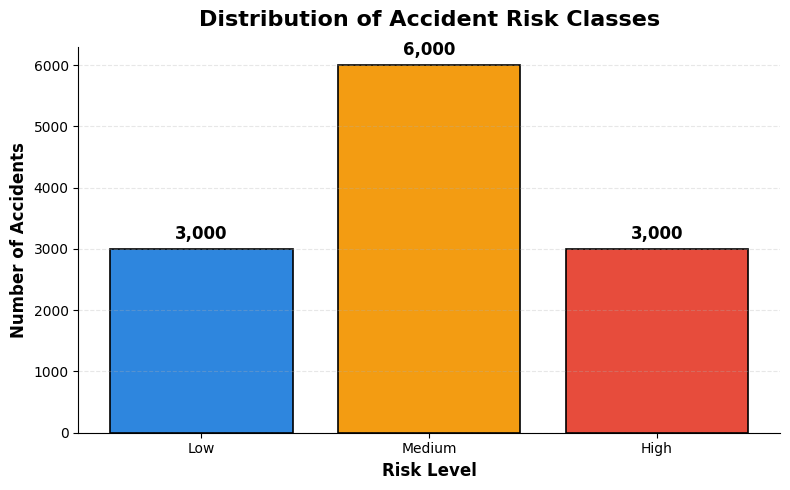

In [ ]:
import matplotlib.pyplot as plt

# Count risk classes
risk_counts = df_model['Risk'].value_counts()

# Correct order
risk_order = ['Low', 'Medium', 'High']
risk_counts = risk_counts.reindex(risk_order)

# Colors
colors = ['#2E86DE', '#F39C12', '#E74C3C']

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    risk_counts.index,
    risk_counts.values,
    color=colors,
    edgecolor='black',
    linewidth=1.2
)

# Add values
for bar, value in zip(bars, risk_counts.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 100,
        f'{value:,}',
        ha='center',
        va='bottom',
        fontsize=12,
        fontweight='bold'
    )

# Title
ax.set_title(
    'Distribution of Accident Risk Classes',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.set_xlabel(
    'Risk Level',
    fontsize=12,
    fontweight='bold'
)

ax.set_ylabel(
    'Number of Accidents',
    fontsize=12,
    fontweight='bold'
)

# Grid
ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

# Remove top/right border
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Save for research paper
plt.savefig(
    'Figure_2_Risk_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
print("Dataset shape:", df_model.shape)

print("\nSeverity distribution:")
print(df_model['Severity'].value_counts().sort_index())

print("\nRisk distribution:")
print(df_model['Risk'].value_counts())

print("\nMissing values:")
print(df_model.isnull().sum())

Dataset shape: (12000, 9)

Severity distribution:
Severity
1    3000
2    6000
3    2000
4    1000
Name: count, dtype: int64

Risk distribution:
Risk
Medium    6000
High      3000
Low       3000
Name: count, dtype: int64

Missing values:
Severity               0
Temperature(F)       281
Humidity(%)          302
Pressure(in)         244
Visibility(mi)       288
Wind_Speed(mph)      334
Precipitation(in)    458
Weather_Condition    268
Risk                   0
dtype: int64


In [ ]:
print("Missing values in each column:")
print(df_model.isnull().sum())
print("Total missing values:", df_model.isnull().sum().sum())

Missing values in each column:
Severity               0
Temperature(F)       281
Humidity(%)          302
Pressure(in)         244
Visibility(mi)       288
Wind_Speed(mph)      334
Precipitation(in)    458
Weather_Condition    268
Risk                   0
dtype: int64
Total missing values: 2175


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Risk classes:")
print(label_encoder.classes_)

print("\nClass mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(label, "=", i)

Risk classes:
['High' 'Low' 'Medium']

Class mapping:
High = 0
Low = 1
Medium = 2


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training records: 9600
Testing records: 2400

Training target distribution:
0    2400
1    2400
2    4800
Name: count, dtype: int64

Testing target distribution:
0     600
1     600
2    1200
Name: count, dtype: int64


In [ ]:
numeric_features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)'
]

categorical_features = [
    'Weather_Condition'
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']

Categorical features:
['Weather_Condition']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical data preprocessing
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Weather condition preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed successfully!")

Logistic Regression training completed successfully!


In [ ]:
y_pred_lr = lr_model.predict(X_test)

print("First 20 predictions:")
print(y_pred_lr[:20])

First 20 predictions:
[2 2 2 2 0 2 2 2 2 2 2 2 1 2 2 2 2 0 2 2]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

lr_weighted_f1 = f1_score(
    y_test,
    y_pred_lr,
    average='weighted',
    zero_division=0
)

lr_macro_f1 = f1_score(
    y_test,
    y_pred_lr,
    average='macro',
    zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)
print("Accuracy       :", round(lr_accuracy, 4))
print("Precision      :", round(lr_precision, 4))
print("Recall         :", round(lr_recall, 4))
print("Weighted F1    :", round(lr_weighted_f1, 4))
print("Macro F1       :", round(lr_macro_f1, 4))

LOGISTIC REGRESSION RESULTS
Accuracy       : 0.5325
Precision      : 0.5261
Recall         : 0.5325
Weighted F1    : 0.4496
Macro F1       : 0.3759


In [ ]:
from sklearn.metrics import classification_report

print("Classification Report - Logistic Regression")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=label_encoder.classes_,
    zero_division=0
))

Classification Report - Logistic Regression
              precision    recall  f1-score   support

        High       0.53      0.03      0.05       600
         Low       0.49      0.34      0.40       600
      Medium       0.54      0.88      0.67      1200

    accuracy                           0.53      2400
   macro avg       0.52      0.42      0.38      2400
weighted avg       0.53      0.53      0.45      2400



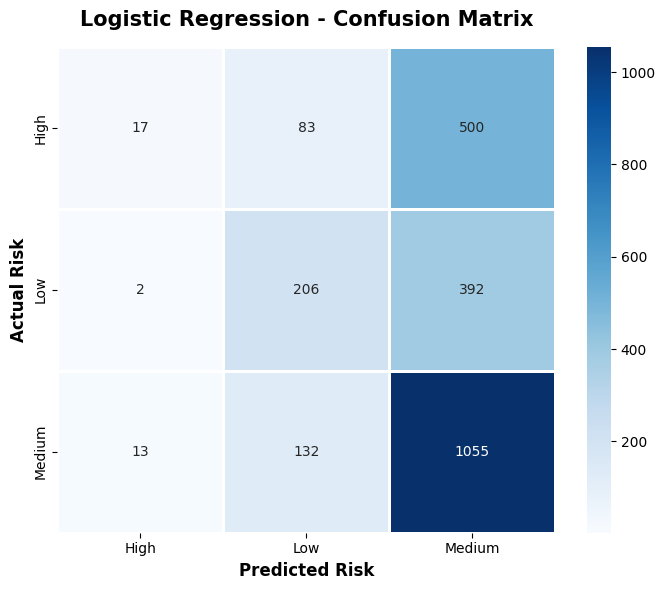

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    linecolor='white',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    'Logistic Regression - Confusion Matrix',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Predicted Risk', fontsize=12, fontweight='bold')
plt.ylabel('Actual Risk', fontsize=12, fontweight='bold')

plt.tight_layout()

plt.savefig(
    'Figure_3_Logistic_Regression_Confusion_Matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [ ]:
y_pred_rf = rf_model.predict(X_test)

print("First 20 Random Forest predictions:")
print(y_pred_rf[:20])

First 20 Random Forest predictions:
[1 2 2 2 0 1 2 2 2 2 2 2 2 2 2 2 1 2 2 2]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test,
    y_pred_rf,
    average='weighted',
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    y_pred_rf,
    average='weighted',
    zero_division=0
)

rf_weighted_f1 = f1_score(
    y_test,
    y_pred_rf,
    average='weighted',
    zero_division=0
)

rf_macro_f1 = f1_score(
    y_test,
    y_pred_rf,
    average='macro',
    zero_division=0
)

print("RANDOM FOREST RESULTS")
print("=" * 40)
print("Accuracy       :", round(rf_accuracy, 4))
print("Precision      :", round(rf_precision, 4))
print("Recall         :", round(rf_recall, 4))
print("Weighted F1    :", round(rf_weighted_f1, 4))
print("Macro F1       :", round(rf_macro_f1, 4))

RANDOM FOREST RESULTS
Accuracy       : 0.6937
Precision      : 0.6533
Recall         : 0.6937
Weighted F1    : 0.658
Macro F1       : 0.6291


In [ ]:
from sklearn.metrics import classification_report

print("Classification Report - Random Forest")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

Classification Report - Random Forest
              precision    recall  f1-score   support

        High       0.43      0.19      0.26       600
         Low       0.83      0.94      0.88       600
      Medium       0.68      0.82      0.74      1200

    accuracy                           0.69      2400
   macro avg       0.64      0.65      0.63      2400
weighted avg       0.65      0.69      0.66      2400



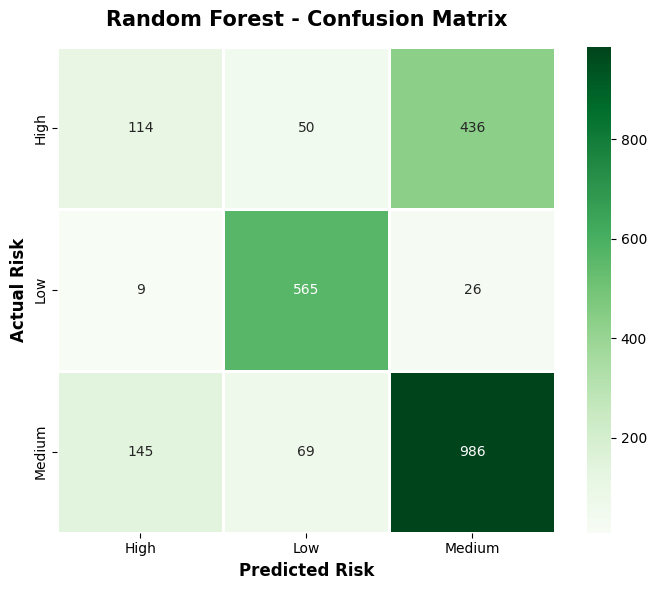

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    linewidths=1,
    linecolor='white',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    'Random Forest - Confusion Matrix',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Predicted Risk', fontsize=12, fontweight='bold')
plt.ylabel('Actual Risk', fontsize=12, fontweight='bold')

plt.tight_layout()

plt.savefig(
    'Figure_4_Random_Forest_Confusion_Matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
print("Total test records:", len(X_test))
print("Total predictions:", len(y_pred_rf))

Total test records: 2400
Total predictions: 2400


In [ ]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss',
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed successfully!")

XGBoost training completed successfully!


In [ ]:
y_pred_xgb = xgb_model.predict(X_test)

print("Total predictions:", len(y_pred_xgb))
print("First 20 predictions:", y_pred_xgb[:20])

Total predictions: 2400
First 20 predictions: [1 0 2 2 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2]


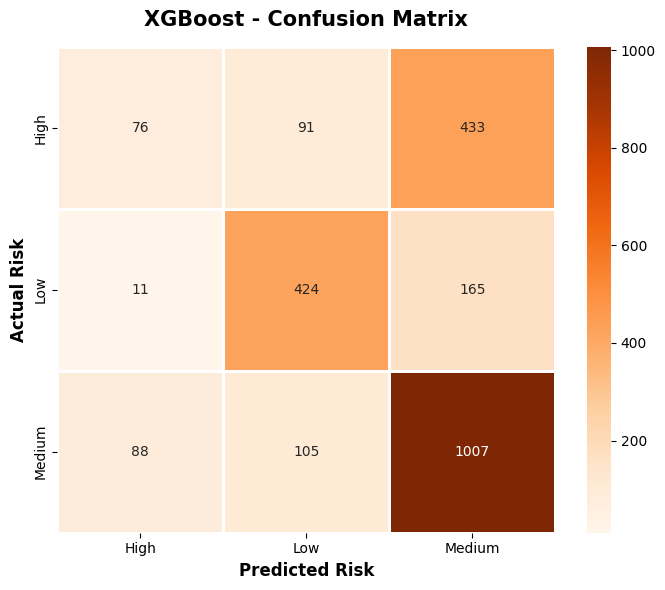

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Oranges',
    linewidths=1,
    linecolor='white',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    'XGBoost - Confusion Matrix',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Predicted Risk', fontsize=12, fontweight='bold')
plt.ylabel('Actual Risk', fontsize=12, fontweight='bold')

plt.tight_layout()

plt.savefig(
    'Figure_5_XGBoost_Confusion_Matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr, average='weighted', zero_division=0),
        precision_score(y_test, y_pred_rf, average='weighted', zero_division=0),
        precision_score(y_test, y_pred_xgb, average='weighted', zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr, average='weighted', zero_division=0),
        recall_score(y_test, y_pred_rf, average='weighted', zero_division=0),
        recall_score(y_test, y_pred_xgb, average='weighted', zero_division=0)
    ],

    'Weighted F1': [
        f1_score(y_test, y_pred_lr, average='weighted', zero_division=0),
        f1_score(y_test, y_pred_rf, average='weighted', zero_division=0),
        f1_score(y_test, y_pred_xgb, average='weighted', zero_division=0)
    ],

    'Macro F1': [
        f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
        f1_score(y_test, y_pred_rf, average='macro', zero_division=0),
        f1_score(y_test, y_pred_xgb, average='macro', zero_division=0)
    ]
})

comparison = comparison.round(4)

print(comparison)

                 Model  Accuracy  Precision  Recall  Weighted F1  Macro F1
0  Logistic Regression    0.5325     0.5261  0.5325       0.4496    0.3759
1        Random Forest    0.6938     0.6533  0.6938       0.6580    0.6291
2              XGBoost    0.6279     0.5932  0.6279       0.5818    0.5364


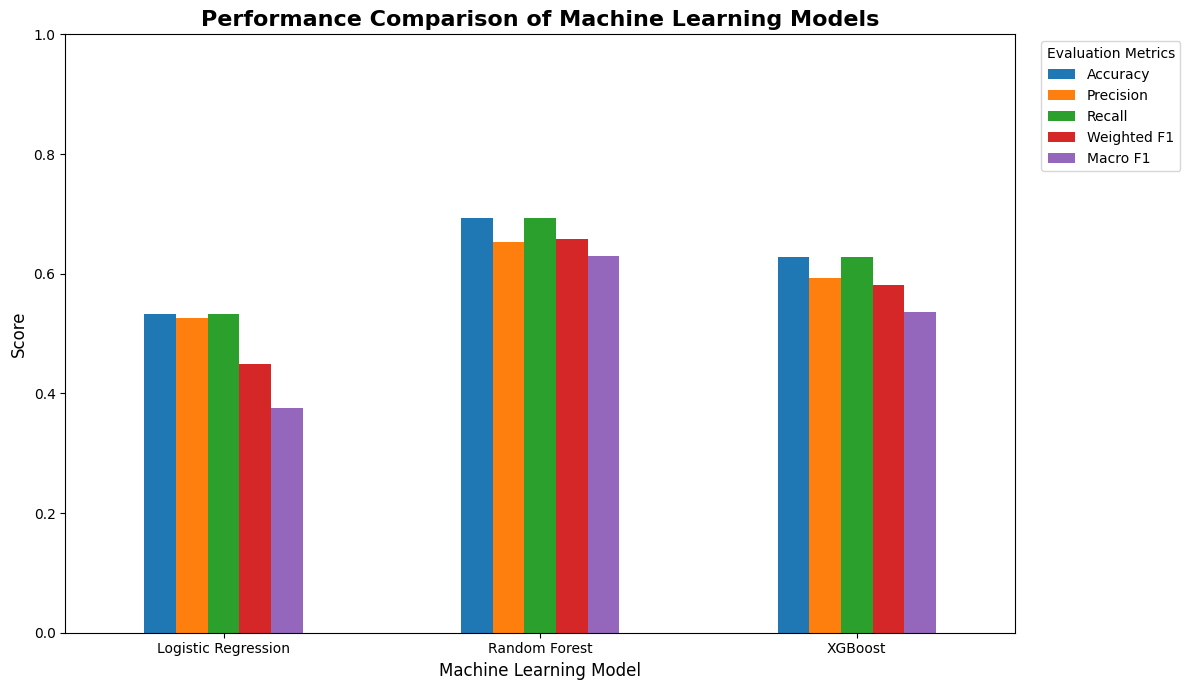

In [ ]:
import matplotlib.pyplot as plt

comparison_plot = comparison.set_index('Model')

ax = comparison_plot.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title(
    'Performance Comparison of Machine Learning Models',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Machine Learning Model', fontsize=12)
plt.ylabel('Score', fontsize=12)

plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.legend(
    title='Evaluation Metrics',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()

plt.savefig(
    'Figure_6_Model_Performance_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:

comparison_percent = comparison.copy()

metric_columns = [
    'Accuracy',
    'Precision',
    'Recall',
    'Weighted F1',
    'Macro F1'
]

comparison_percent[metric_columns] = (
    comparison_percent[metric_columns] * 100
).round(2)

display(comparison_percent)

,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Logistic Regression,53.25,52.61,53.25,44.96,37.59
1,Random Forest,69.38,65.33,69.38,65.80,62.91
2,XGBoost,62.79,59.32,62.79,58.18,53.64


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

baseline = DummyClassifier(
    strategy='most_frequent'
)

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

print("BASELINE RESULTS")
print("=" * 40)

print("Accuracy :", round(
    accuracy_score(y_test, y_pred_baseline), 4
))

print("Macro F1 :", round(
    f1_score(y_test, y_pred_baseline, average='macro'),
    4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=label_encoder.classes_,
    zero_division=0
))

BASELINE RESULTS
Accuracy : 0.5
Macro F1 : 0.2222

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00       600
         Low       0.00      0.00      0.00       600
      Medium       0.50      1.00      0.67      1200

    accuracy                           0.50      2400
   macro avg       0.17      0.33      0.22      2400
weighted avg       0.25      0.50      0.33      2400



In [ ]:
print("RANDOM FOREST - DETAILED VALIDATION")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

RANDOM FOREST - DETAILED VALIDATION
              precision    recall  f1-score   support

        High       0.43      0.19      0.26       600
         Low       0.83      0.94      0.88       600
      Medium       0.68      0.82      0.74      1200

    accuracy                           0.69      2400
   macro avg       0.64      0.65      0.63      2400
weighted avg       0.65      0.69      0.66      2400



In [ ]:
!pip install shap -q

In [ ]:
import shap
import numpy as np
import pandas as pd

# Get the trained Random Forest classifier
rf_classifier = rf_model.named_steps['classifier']

# Transform test data using the already fitted preprocessor
X_test_transformed = rf_model.named_steps['preprocessor'].transform(X_test)

# Get transformed feature names
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

print("Transformed data shape:", X_test_transformed.shape)
print("Number of features:", len(feature_names))

Transformed data shape: (2400, 45)
Number of features: 45


In [ ]:
# Convert transformed test data into a dense numeric NumPy array

X_test_shap = X_test_transformed.toarray() if hasattr(
    X_test_transformed, "toarray"
) else np.asarray(X_test_transformed)

X_test_shap = X_test_shap.astype(np.float64)

print("SHAP input shape:", X_test_shap.shape)
print("SHAP input dtype:", X_test_shap.dtype)

SHAP input shape: (2400, 45)
SHAP input dtype: float64


In [ ]:
import shap
import numpy as np
import pandas as pd

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [ ]:
import pandas as pd
import numpy as np
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

In [ ]:
df = pd.read_csv("US_Accidents_2022_April_September_12000.csv")

print(df.shape)

(12000, 9)


In [ ]:
features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)',
    'Weather_Condition'
]

df_model = df[['Severity'] + features].copy()

def convert_risk(severity):
    if severity == 1:
        return 'Low'
    elif severity == 2:
        return 'Medium'
    elif severity in [3, 4]:
        return 'High'

df_model['Risk'] = df_model['Severity'].apply(convert_risk)

X = df_model[features].copy()
y = df_model['Risk'].copy()

print(df_model['Risk'].value_counts())

Risk
Medium    6000
High      3000
Low       3000
Name: count, dtype: int64


In [ ]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (9600, 7)
Testing: (2400, 7)


In [ ]:
numeric_features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)'
]

categorical_features = ['Weather_Condition']

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
rf_classifier = rf_model.named_steps['classifier']

X_test_transformed = rf_model.named_steps['preprocessor'].transform(X_test)

X_test_shap = X_test_transformed.toarray() if hasattr(
    X_test_transformed, "toarray"
) else np.asarray(X_test_transformed)

X_test_shap = X_test_shap.astype(np.float64)

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

print("SHAP input shape:", X_test_shap.shape)
print("SHAP input dtype:", X_test_shap.dtype)

SHAP input shape: (2400, 45)
SHAP input dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Load dataset
df = pd.read_csv("US_Accidents_2022_April_September_12000.csv")

# Weather features
features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)',
    'Weather_Condition'
]

# Prepare data
df_model = df[['Severity'] + features].copy()

# Convert Severity to Risk
def convert_risk(severity):
    if severity == 1:
        return 'Low'
    elif severity == 2:
        return 'Medium'
    elif severity in [3, 4]:
        return 'High'

df_model['Risk'] = df_model['Severity'].apply(convert_risk)

X = df_model[features].copy()
y = df_model['Risk'].copy()

# Encode target
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Feature types
numeric_features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)'
]

categorical_features = ['Weather_Condition']

# Preprocessing
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Random Forest
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Random Forest trained successfully!
Training samples: 9600
Testing samples: 2400


In [ ]:
rf_classifier = rf_model.named_steps['classifier']

print("Random Forest classifier loaded successfully!")

Random Forest classifier loaded successfully!


In [ ]:
X_test_transformed = rf_model.named_steps['preprocessor'].transform(X_test)

X_test_shap = X_test_transformed.toarray() if hasattr(
    X_test_transformed, "toarray"
) else np.asarray(X_test_transformed)

X_test_shap = X_test_shap.astype(np.float64)

# Only 300 samples for SHAP
X_test_shap_small = X_test_shap[:300]

feature_names = rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

print("SHAP input shape:", X_test_shap_small.shape)
print("SHAP input dtype:", X_test_shap_small.dtype)

SHAP input shape: (300, 45)
SHAP input dtype: float64


In [ ]:
explainer = shap.TreeExplainer(rf_classifier)

shap_values = explainer.shap_values(X_test_shap_small)

print("SHAP values calculated successfully!")
print("SHAP type:", type(shap_values))

SHAP values calculated successfully!
SHAP type: <class 'numpy.ndarray'>


In [ ]:
print("SHAP values shape:", shap_values.shape)
print("SHAP input shape:", X_test_shap_small.shape)
print("Number of feature names:", len(feature_names))

SHAP values shape: (300, 45, 3)
SHAP input shape: (300, 45)
Number of feature names: 45


In [ ]:
# Mean absolute SHAP importance across samples and classes
mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))

shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by='SHAP Importance',
    ascending=False
)

print(shap_importance.head(15))

                                           Feature  SHAP Importance
1                                 num__Humidity(%)         0.071079
2                                num__Pressure(in)         0.063430
0                              num__Temperature(F)         0.037673
4                             num__Wind_Speed(mph)         0.036716
9                      cat__Weather_Condition_Fair         0.015011
26            cat__Weather_Condition_Mostly Cloudy         0.011290
3                              num__Visibility(mi)         0.008222
29            cat__Weather_Condition_Partly Cloudy         0.006619
6                    cat__Weather_Condition_Cloudy         0.006457
5                           num__Precipitation(in)         0.004127
19               cat__Weather_Condition_Light Rain         0.003089
42  cat__Weather_Condition_Thunder in the Vicinity         0.001144
11                      cat__Weather_Condition_Fog         0.001042
40                  cat__Weather_Condition_Thund

In [ ]:
importance_original = {}

for feature, importance in zip(
    feature_names,
    mean_abs_shap
):

    if feature.startswith('num__'):
        original_name = feature.replace('num__', '')

    elif feature.startswith('cat__Weather_Condition'):
        original_name = 'Weather_Condition'

    else:
        original_name = feature

    importance_original[original_name] = (
        importance_original.get(original_name, 0) + importance
    )

shap_original = pd.DataFrame(
    list(importance_original.items()),
    columns=['Weather Factor', 'SHAP Importance']
)

shap_original = shap_original.sort_values(
    by='SHAP Importance',
    ascending=False
)

print(shap_original)

      Weather Factor  SHAP Importance
1        Humidity(%)         0.071079
2       Pressure(in)         0.063430
6  Weather_Condition         0.049019
0     Temperature(F)         0.037673
4    Wind_Speed(mph)         0.036716
3     Visibility(mi)         0.008222
5  Precipitation(in)         0.004127


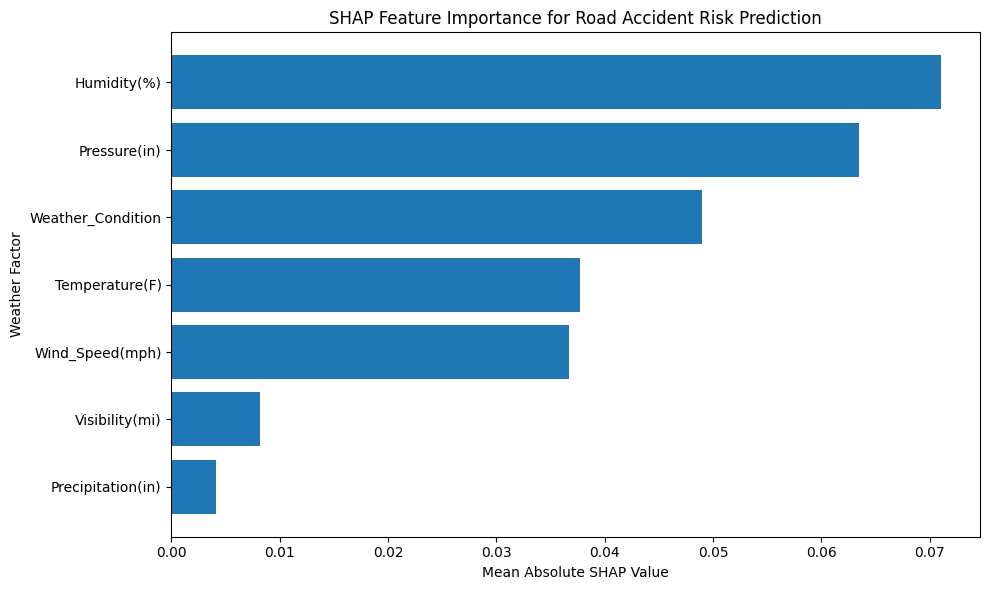

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    shap_original['Weather Factor'],
    shap_original['SHAP Importance']
)

plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Weather Factor')
plt.title('SHAP Feature Importance for Road Accident Risk Prediction')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
print("SHAP values shape:", shap_values.shape)
print("Classes:", label_encoder.classes_)

SHAP values shape: (300, 45, 3)
Classes: ['High' 'Low' 'Medium']


In [ ]:
high_index = list(label_encoder.classes_).index('High')

high_shap_values = shap_values[:, :, high_index]

high_importance = np.abs(high_shap_values).mean(axis=0)

high_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': high_importance
})

high_df = high_df.sort_values(
    by='SHAP Importance',
    ascending=False
)

print("Top features for HIGH Risk:")
print(high_df.head(15))

Top features for HIGH Risk:
                                           Feature  SHAP Importance
2                                num__Pressure(in)         0.050431
1                                 num__Humidity(%)         0.036272
4                             num__Wind_Speed(mph)         0.026180
0                              num__Temperature(F)         0.025192
9                      cat__Weather_Condition_Fair         0.010873
26            cat__Weather_Condition_Mostly Cloudy         0.008193
3                              num__Visibility(mi)         0.006735
6                    cat__Weather_Condition_Cloudy         0.004928
29            cat__Weather_Condition_Partly Cloudy         0.004691
5                           num__Precipitation(in)         0.003195
19               cat__Weather_Condition_Light Rain         0.003086
42  cat__Weather_Condition_Thunder in the Vicinity         0.001239
11                      cat__Weather_Condition_Fog         0.000993
38                  

In [ ]:
medium_index = list(label_encoder.classes_).index('Medium')

medium_shap_values = shap_values[:, :, medium_index]

medium_importance = np.abs(medium_shap_values).mean(axis=0)

medium_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': medium_importance
})

medium_df = medium_df.sort_values(
    by='SHAP Importance',
    ascending=False
)

print("Top features for MEDIUM Risk:")
print(medium_df.head(15))

Top features for MEDIUM Risk:
                                           Feature  SHAP Importance
1                                 num__Humidity(%)         0.081338
2                                num__Pressure(in)         0.078987
0                              num__Temperature(F)         0.041718
4                             num__Wind_Speed(mph)         0.037937
9                      cat__Weather_Condition_Fair         0.015504
26            cat__Weather_Condition_Mostly Cloudy         0.011653
3                              num__Visibility(mi)         0.007614
29            cat__Weather_Condition_Partly Cloudy         0.007283
6                    cat__Weather_Condition_Cloudy         0.006171
5                           num__Precipitation(in)         0.003642
19               cat__Weather_Condition_Light Rain         0.002231
42  cat__Weather_Condition_Thunder in the Vicinity         0.001456
11                      cat__Weather_Condition_Fog         0.000710
7            cat__

In [ ]:
low_index = list(label_encoder.classes_).index('Low')

low_shap_values = shap_values[:, :, low_index]

low_importance = np.abs(low_shap_values).mean(axis=0)

low_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': low_importance
})

low_df = low_df.sort_values(
    by='SHAP Importance',
    ascending=False
)

print("Top features for LOW Risk:")
print(low_df.head(15))

Top features for LOW Risk:
                                           Feature  SHAP Importance
1                                 num__Humidity(%)         0.095627
2                                num__Pressure(in)         0.060872
0                              num__Temperature(F)         0.046111
4                             num__Wind_Speed(mph)         0.046029
9                      cat__Weather_Condition_Fair         0.018654
26            cat__Weather_Condition_Mostly Cloudy         0.014024
3                              num__Visibility(mi)         0.010316
6                    cat__Weather_Condition_Cloudy         0.008271
29            cat__Weather_Condition_Partly Cloudy         0.007885
5                           num__Precipitation(in)         0.005544
19               cat__Weather_Condition_Light Rain         0.003950
11                      cat__Weather_Condition_Fog         0.001421
42  cat__Weather_Condition_Thunder in the Vicinity         0.000738
40                  c

In [ ]:
import numpy as np
import pandas as pd

# Original 7 weather factors
original_features = [
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Speed(mph)',
    'Precipitation(in)',
    'Weather_Condition'
]

def aggregate_shap(shap_class, feature_names):
    result = {}

    for original_feature in original_features:
        matching_indices = [
            i for i, name in enumerate(feature_names)
            if original_feature in name
        ]

        if len(matching_indices) > 0:
            # Combine all encoded columns belonging to this factor
            result[original_feature] = np.abs(
                shap_class[:, matching_indices]
            ).mean()

    return pd.DataFrame(
        list(result.items()),
        columns=['Weather Factor', 'SHAP Importance']
    ).sort_values(
        'SHAP Importance',
        ascending=False
    )

# Class indexes
high_index = list(label_encoder.classes_).index('High')
medium_index = list(label_encoder.classes_).index('Medium')
low_index = list(label_encoder.classes_).index('Low')

# SHAP values for each class
high_shap = shap_values[:, :, high_index]
medium_shap = shap_values[:, :, medium_index]
low_shap = shap_values[:, :, low_index]

# Aggregate
high_original = aggregate_shap(high_shap, feature_names)
medium_original = aggregate_shap(medium_shap, feature_names)
low_original = aggregate_shap(low_shap, feature_names)

print("========== HIGH RISK ==========")
print(high_original)

print("\n========== MEDIUM RISK ==========")
print(medium_original)

print("\n========== LOW RISK ==========")
print(low_original)

========== HIGH RISK ==========
      Weather Factor  SHAP Importance
2       Pressure(in)         0.050431
1        Humidity(%)         0.036272
4    Wind_Speed(mph)         0.026180
0     Temperature(F)         0.025192
3     Visibility(mi)         0.006735
5  Precipitation(in)         0.003195
6  Weather_Condition         0.000983

========== MEDIUM RISK ==========
      Weather Factor  SHAP Importance
1        Humidity(%)         0.081338
2       Pressure(in)         0.078987
0     Temperature(F)         0.041718
4    Wind_Speed(mph)         0.037937
3     Visibility(mi)         0.007614
5  Precipitation(in)         0.003642
6  Weather_Condition         0.001264

========== LOW RISK ==========
      Weather Factor  SHAP Importance
1        Humidity(%)         0.095627
2       Pressure(in)         0.060872
0     Temperature(F)         0.046111
4    Wind_Speed(mph)         0.046029
3     Visibility(mi)         0.010316
5  Precipitation(in)         0.005544
6  Weather_Condition       

In [ ]:
# ==========================================
# SHAP DIRECTION ANALYSIS - HIGH RISK
# ==========================================

# Get High Risk SHAP values
high_index = list(label_encoder.classes_).index('High')
high_shap = shap_values[:, :, high_index]

# Mean signed SHAP value
high_direction = high_shap.mean(axis=0)

high_direction_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean SHAP': high_direction
})

high_direction_df = high_direction_df.sort_values(
    by='Mean SHAP',
    ascending=False
)

print("SHAP DIRECTION FOR HIGH RISK")
print("=" * 50)
print(high_direction_df.head(20))

SHAP DIRECTION FOR HIGH RISK
                                             Feature  Mean SHAP
11                        cat__Weather_Condition_Fog   0.000237
41            cat__Weather_Condition_Thunder / Windy   0.000128
27      cat__Weather_Condition_Mostly Cloudy / Windy   0.000122
34                cat__Weather_Condition_Shallow Fog   0.000118
13                       cat__Weather_Condition_Haze   0.000059
36                      cat__Weather_Condition_Smoke   0.000042
16              cat__Weather_Condition_Heavy T-Storm   0.000041
31             cat__Weather_Condition_Patches of Fog   0.000029
10               cat__Weather_Condition_Fair / Windy   0.000026
42    cat__Weather_Condition_Thunder in the Vicinity   0.000025
33               cat__Weather_Condition_Rain / Windy   0.000016
24  cat__Weather_Condition_Light Snow Shower / Windy   0.000016
44                 cat__Weather_Condition_Wintry Mix   0.000010
25                       cat__Weather_Condition_Mist   0.000009
17      cat

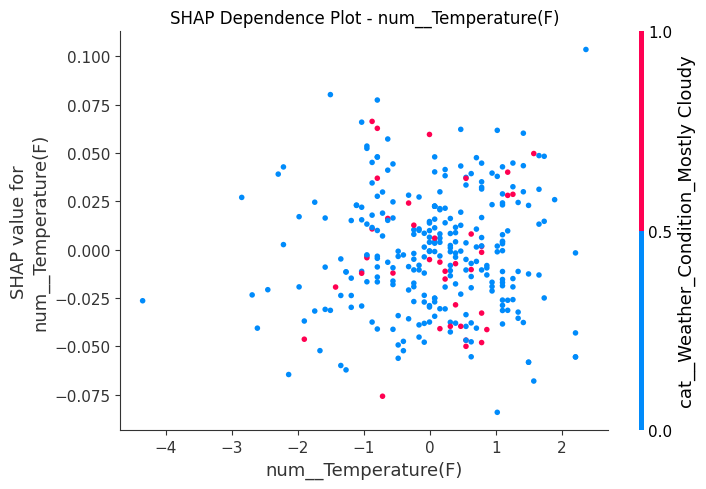

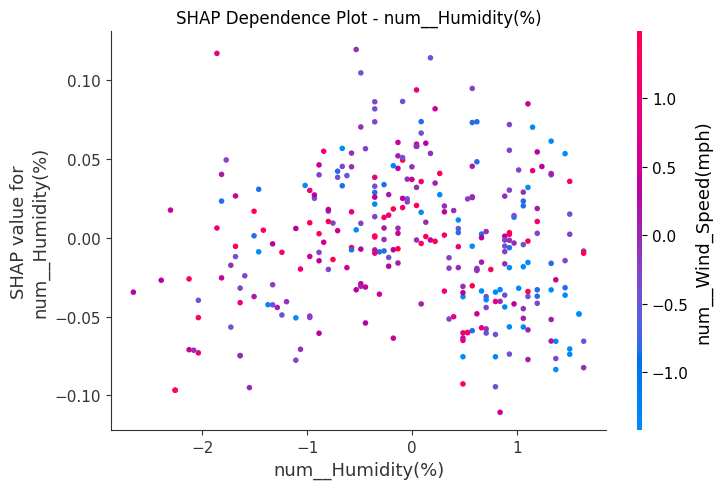

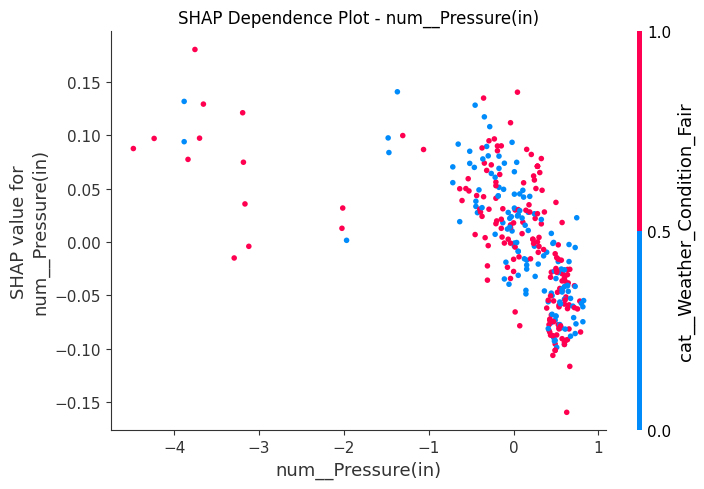

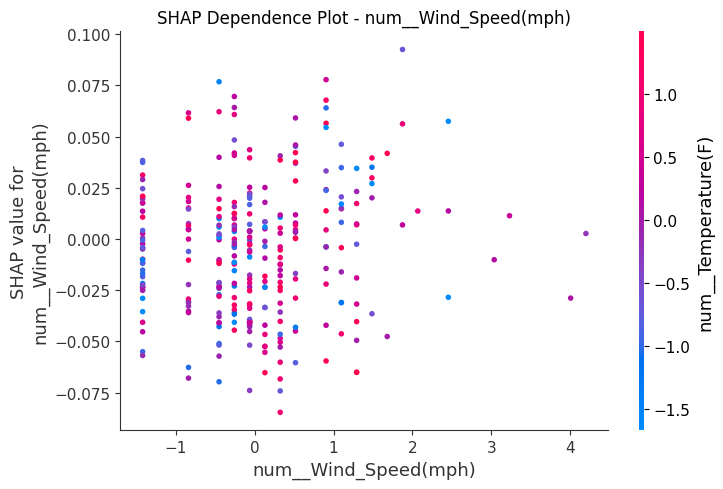

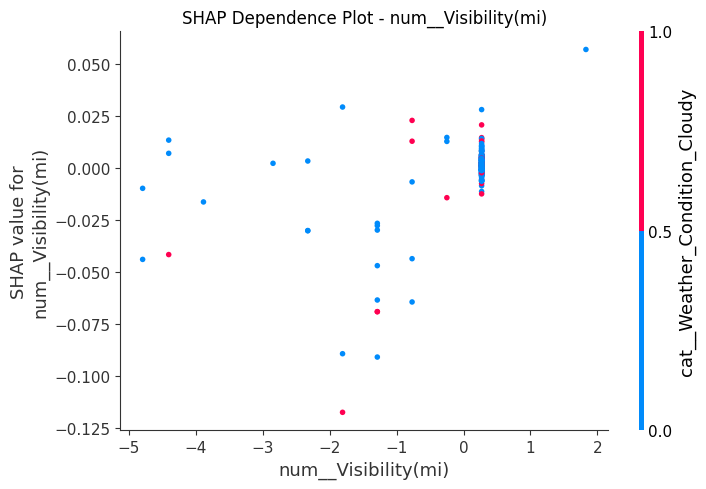

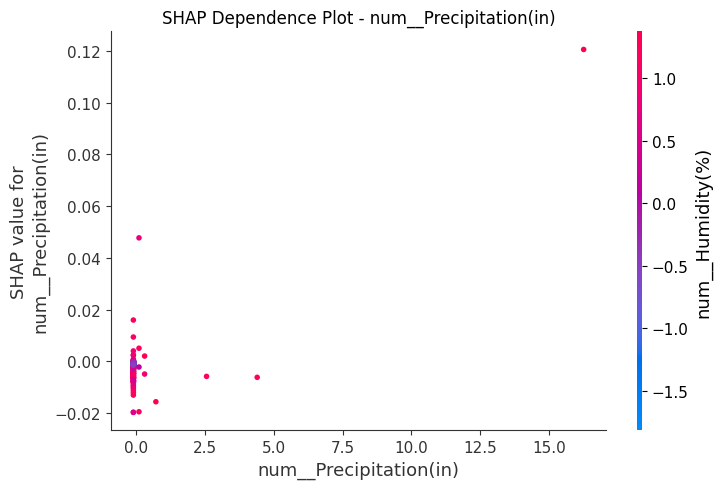

In [ ]:
# ==========================================
# SHAP DEPENDENCE ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import shap

# High Risk class index
high_index = list(label_encoder.classes_).index('High')

# High Risk SHAP values
high_shap = shap_values[:, :, high_index]

# Important numerical features
important_features = [
    'num__Temperature(F)',
    'num__Humidity(%)',
    'num__Pressure(in)',
    'num__Wind_Speed(mph)',
    'num__Visibility(mi)',
    'num__Precipitation(in)'
]

# Plot dependence for each feature
for feature in important_features:

    shap.dependence_plot(
        feature,
        high_shap,
        X_test_shap_small,
        feature_names=feature_names,
        show=False
    )

    plt.title(f"SHAP Dependence Plot - {feature}")
    plt.tight_layout()
    plt.show()

In [ ]:
# ==========================================
# INDIVIDUAL WEATHER INPUT PREDICTION
# ==========================================

import pandas as pd
import numpy as np

# User weather input
new_data = pd.DataFrame({
    'Temperature(F)': [80],
    'Humidity(%)': [70],
    'Pressure(in)': [29.5],
    'Visibility(mi)': [5],
    'Wind_Speed(mph)': [15],
    'Precipitation(in)': [0.2],
    'Weather_Condition': ['Rain']
})

# Prediction
prediction = rf_model.predict(new_data)

# Prediction probability
probability = rf_model.predict_proba(new_data)

# Convert prediction back to risk name
predicted_risk = label_encoder.inverse_transform(prediction)[0]

print("======================================")
print("       ROAD ACCIDENT RISK")
print("======================================")

print("Predicted Risk:", predicted_risk)

print("\nPrediction Probability:")

for class_name, prob in zip(label_encoder.classes_, probability[0]):
    print(f"{class_name}: {prob:.4f}")

       ROAD ACCIDENT RISK
Predicted Risk: Medium

Prediction Probability:
High: 0.2350
Low: 0.0400
Medium: 0.7250


In [ ]:
# ==========================================
# SHAP EXPLANATION FOR SINGLE INPUT
# ==========================================

# Transform the new input using the fitted preprocessor
new_data_transformed = rf_model.named_steps['preprocessor'].transform(new_data)

# Convert to dense float64
new_data_shap = (
    new_data_transformed.toarray()
    if hasattr(new_data_transformed, "toarray")
    else np.asarray(new_data_transformed)
)

new_data_shap = new_data_shap.astype(np.float64)

# Create SHAP explainer
explainer_single = shap.TreeExplainer(rf_classifier)

# Calculate SHAP values
single_shap_values = explainer_single.shap_values(new_data_shap)

print("SHAP explanation calculated successfully!")
print("SHAP shape:", single_shap_values.shape)

SHAP explanation calculated successfully!
SHAP shape: (1, 45, 3)


In [ ]:
# ==========================================
# INDIVIDUAL INPUT - MEDIUM RISK SHAP
# ==========================================

# Medium Risk class index
medium_index = list(label_encoder.classes_).index('Medium')

# SHAP values for Medium Risk
medium_single_shap = single_shap_values[0, :, medium_index]

# Create SHAP contribution table
single_shap_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Value': medium_single_shap
})

# Sort by absolute contribution
single_shap_df['Absolute SHAP'] = np.abs(
    single_shap_df['SHAP Value']
)

single_shap_df = single_shap_df.sort_values(
    by='Absolute SHAP',
    ascending=False
)

print("==========================================")
print("SHAP EXPLANATION - MEDIUM RISK")
print("==========================================")

print(single_shap_df.head(15).to_string(index=False))

SHAP EXPLANATION - MEDIUM RISK
                                  Feature  SHAP Value  Absolute SHAP
                     num__Wind_Speed(mph)    0.086307       0.086307
                   num__Precipitation(in)    0.038128       0.038128
              cat__Weather_Condition_Rain    0.025839       0.025839
                         num__Humidity(%)    0.022490       0.022490
                      num__Visibility(mi)    0.018603       0.018603
                        num__Pressure(in)   -0.014007       0.014007
              cat__Weather_Condition_Fair    0.011879       0.011879
     cat__Weather_Condition_Partly Cloudy    0.006912       0.006912
                      num__Temperature(F)    0.006289       0.006289
            cat__Weather_Condition_Cloudy    0.005887       0.005887
     cat__Weather_Condition_Mostly Cloudy    0.004501       0.004501
        cat__Weather_Condition_Light Rain    0.003253       0.003253
              cat__Weather_Condition_Haze    0.002881       0.002881
   

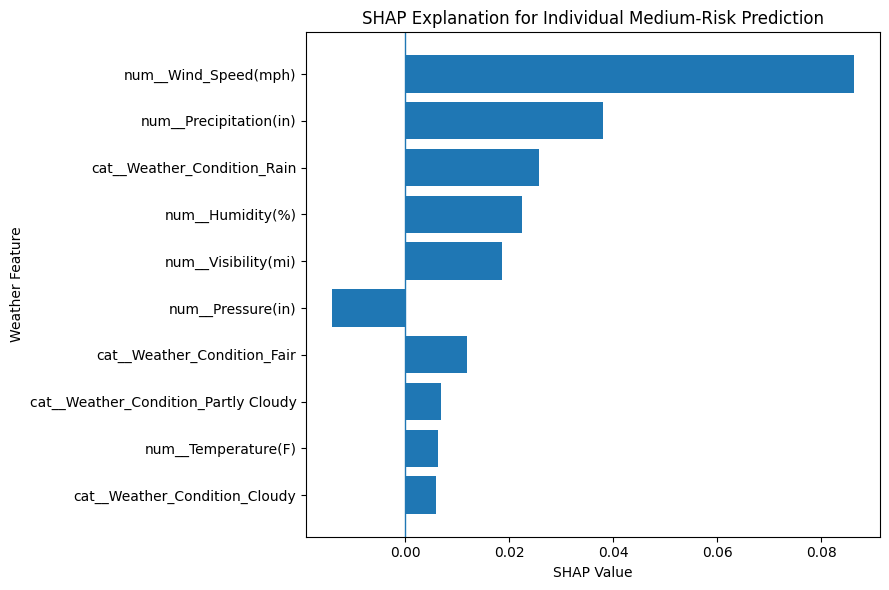

In [ ]:
# ==========================================
# SHAP BAR CHART - MEDIUM RISK
# ==========================================

top_features = single_shap_df.head(10).copy()

plt.figure(figsize=(9, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['SHAP Value'][::-1]
)

plt.axvline(0, linewidth=1)

plt.xlabel("SHAP Value")
plt.ylabel("Weather Feature")
plt.title("SHAP Explanation for Individual Medium-Risk Prediction")

plt.tight_layout()
plt.show()

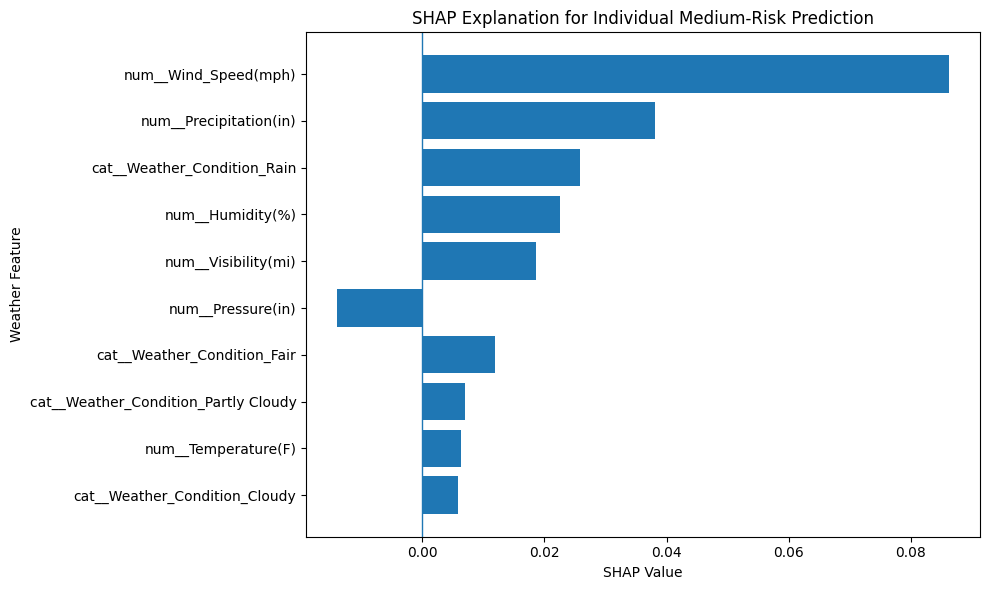

In [ ]:
# ==========================================
# INDIVIDUAL SHAP EXPLANATION - BAR CHART
# ==========================================

top_features = single_shap_df.head(10).copy()

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['SHAP Value'][::-1]
)

plt.axvline(0, linewidth=1)

plt.xlabel("SHAP Value")
plt.ylabel("Weather Feature")
plt.title("SHAP Explanation for Individual Medium-Risk Prediction")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# TEST 3 WEATHER SCENARIOS
# ==========================================

scenarios = pd.DataFrame({
    'Temperature(F)': [75, 65, 60],
    'Humidity(%)': [50, 85, 90],
    'Pressure(in)': [30.0, 29.5, 29.0],
    'Visibility(mi)': [10, 3, 1],
    'Wind_Speed(mph)': [5, 15, 25],
    'Precipitation(in)': [0, 0.5, 1.0],
    'Weather_Condition': ['Fair', 'Rain', 'Heavy Rain']
})

predictions = rf_model.predict(scenarios)
probabilities = rf_model.predict_proba(scenarios)

predicted_risks = label_encoder.inverse_transform(predictions)

results = scenarios.copy()
results['Predicted Risk'] = predicted_risks

for i, class_name in enumerate(label_encoder.classes_):
    results[f'{class_name} Probability'] = probabilities[:, i]

print("==========================================")
print("       3 WEATHER SCENARIO RESULTS")
print("==========================================")

print(results.to_string(index=False))

       3 WEATHER SCENARIO RESULTS
 Temperature(F)  Humidity(%)  Pressure(in)  Visibility(mi)  Wind_Speed(mph)  Precipitation(in) Weather_Condition Predicted Risk  High Probability  Low Probability  Medium Probability
             75           50          30.0              10                5                0.0              Fair         Medium             0.455            0.065                0.48
             65           85          29.5               3               15                0.5              Rain         Medium             0.360            0.090                0.55
             60           90          29.0               1               25                1.0        Heavy Rain           High             0.505            0.055                0.44


In [ ]:
# ==========================================
# SHAP EXPLANATION FOR 3 SCENARIOS
# ==========================================

# Transform the 3 scenarios
scenarios_transformed = rf_model.named_steps['preprocessor'].transform(scenarios)

# Convert to dense float64
if hasattr(scenarios_transformed, "toarray"):
    scenarios_shap = scenarios_transformed.toarray()
else:
    scenarios_shap = np.asarray(scenarios_transformed)

scenarios_shap = scenarios_shap.astype(np.float64)

# Calculate SHAP values
scenario_shap_values = explainer_single.shap_values(scenarios_shap)

print("SHAP values calculated successfully!")
print("SHAP shape:", scenario_shap_values.shape)

SHAP values calculated successfully!
SHAP shape: (3, 45, 3)


In [ ]:
# ==========================================
# SHAP EXPLANATION FOR 3 SCENARIOS
# ==========================================

# Get predicted class for each scenario
scenario_predictions = rf_model.predict(scenarios)
scenario_risks = label_encoder.inverse_transform(scenario_predictions)

print("==========================================")
print("SHAP EXPLANATION FOR EACH SCENARIO")
print("==========================================")

for i in range(len(scenarios)):

    # Predicted class index
    predicted_class_index = scenario_predictions[i]

    # SHAP values for predicted class
    shap_for_prediction = scenario_shap_values[
        i, :, predicted_class_index
    ]

    # Create dataframe
    temp_df = pd.DataFrame({
        'Feature': feature_names,
        'SHAP Value': shap_for_prediction
    })

    temp_df['Absolute SHAP'] = np.abs(temp_df['SHAP Value'])

    # Sort by contribution strength
    temp_df = temp_df.sort_values(
        by='Absolute SHAP',
        ascending=False
    )

    print("\n==========================================")
    print(f"SCENARIO {i+1}")
    print("Weather:", scenarios.iloc[i]['Weather_Condition'])
    print("Predicted Risk:", scenario_risks[i])
    print("==========================================")

    print(
        temp_df.head(10).to_string(index=False)
    )

SHAP EXPLANATION FOR EACH SCENARIO

SCENARIO 1
Weather: Fair
Predicted Risk: Medium
                                       Feature  SHAP Value  Absolute SHAP
                          num__Wind_Speed(mph)   -0.063998       0.063998
                             num__Pressure(in)    0.058218       0.058218
                           num__Temperature(F)   -0.038150       0.038150
                              num__Humidity(%)    0.025609       0.025609
                   cat__Weather_Condition_Fair   -0.003609       0.003609
                 cat__Weather_Condition_Cloudy    0.002338       0.002338
          cat__Weather_Condition_Partly Cloudy    0.001988       0.001988
                        num__Precipitation(in)   -0.001373       0.001373
cat__Weather_Condition_Thunder in the Vicinity   -0.000938       0.000938
             cat__Weather_Condition_Light Rain   -0.000838       0.000838

SCENARIO 2
Weather: Rain
Predicted Risk: Medium
                                     Feature  SHAP Va

In [ ]:
# ==========================================
# AUTOMATIC TEXT-BASED SHAP EXPLANATION
# ==========================================

# Predicted class
predicted_class_index = prediction[0]
predicted_risk = label_encoder.inverse_transform(
    [predicted_class_index]
)[0]

# SHAP values for predicted class
predicted_shap = single_shap_values[
    0, :, predicted_class_index
]

# Create dataframe
explanation_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Value': predicted_shap
})

# ------------------------------------------
# Keep numerical features
# ------------------------------------------

numeric_names = [
    'num__Temperature(F)',
    'num__Humidity(%)',
    'num__Pressure(in)',
    'num__Visibility(mi)',
    'num__Wind_Speed(mph)',
    'num__Precipitation(in)'
]

numeric_df = explanation_df[
    explanation_df['Feature'].isin(numeric_names)
].copy()

# ------------------------------------------
# Keep ONLY the actual weather condition
# entered by the user
# ------------------------------------------

weather_value = new_data['Weather_Condition'].iloc[0]

weather_feature_name = (
    'cat__Weather_Condition_' + weather_value
)

weather_df = explanation_df[
    explanation_df['Feature'] == weather_feature_name
].copy()

# Combine
final_explanation_df = pd.concat(
    [numeric_df, weather_df],
    ignore_index=True
)

# Add absolute SHAP
final_explanation_df['Absolute SHAP'] = np.abs(
    final_explanation_df['SHAP Value']
)

# Sort by strength
final_explanation_df = final_explanation_df.sort_values(
    by='Absolute SHAP',
    ascending=False
)

# ------------------------------------------
# Display prediction
# ------------------------------------------

print("=" * 60)
print("          ROAD ACCIDENT RISK PREDICTION")
print("=" * 60)

print(f"\nPredicted Risk: {predicted_risk}")

print("\nPrediction Probability:")

for class_name, prob in zip(
    label_encoder.classes_,
    probability[0]
):
    print(f"{class_name}: {prob*100:.2f}%")

# ------------------------------------------
# Positive and negative contributors
# ------------------------------------------

positive = final_explanation_df[
    final_explanation_df['SHAP Value'] > 0
].head(3)

negative = final_explanation_df[
    final_explanation_df['SHAP Value'] < 0
].head(3)

# ------------------------------------------
# Convert feature names to simple names
# ------------------------------------------

def simple_feature_name(feature):

    feature = feature.replace('num__', '')
    feature = feature.replace('cat__Weather_Condition_', 'Weather Condition: ')

    return feature

# ------------------------------------------
# TEXT EXPLANATION
# ------------------------------------------

print("\n" + "=" * 60)
print("              SHAP EXPLANATION")
print("=" * 60)

print(
    f"\nThe model predicts {predicted_risk} Risk "
    f"for the given weather conditions."
)

if len(positive) > 0:

    print("\nFactors increasing the predicted risk:")

    for _, row in positive.iterrows():

        name = simple_feature_name(row['Feature'])

        print(
            f"• {name} is contributing toward "
            f"{predicted_risk} Risk."
        )

if len(negative) > 0:

    print("\nFactors reducing the predicted risk:")

    for _, row in negative.iterrows():

        name = simple_feature_name(row['Feature'])

        print(
            f"• {name} is contributing away from "
            f"{predicted_risk} Risk."
        )

print("\nNote: SHAP explains the model's prediction "
      "for this specific input; it does not establish causation.")

          ROAD ACCIDENT RISK PREDICTION

Predicted Risk: Medium

Prediction Probability:
High: 23.50%
Low: 4.00%
Medium: 72.50%

              SHAP EXPLANATION

The model predicts Medium Risk for the given weather conditions.

Factors increasing the predicted risk:
• Wind_Speed(mph) is contributing toward Medium Risk.
• Precipitation(in) is contributing toward Medium Risk.
• Weather Condition: Rain is contributing toward Medium Risk.

Factors reducing the predicted risk:
• Pressure(in) is contributing away from Medium Risk.

Note: SHAP explains the model's prediction for this specific input; it does not establish causation.


In [ ]:
# ============================================================
# FINAL WEATHER-BASED ROAD ACCIDENT RISK PREDICTION + SHAP
# ============================================================

def predict_accident_risk():

    print("=" * 60)
    print("       WEATHER-BASED ROAD ACCIDENT RISK")
    print("=" * 60)

    # -----------------------------
    # 1. USER INPUT
    # -----------------------------

    temperature = float(input("Enter Temperature (°F): "))
    humidity = float(input("Enter Humidity (%): "))
    pressure = float(input("Enter Pressure (in): "))
    visibility = float(input("Enter Visibility (mi): "))
    wind_speed = float(input("Enter Wind Speed (mph): "))
    precipitation = float(input("Enter Precipitation (in): "))
    weather = input("Enter Weather Condition: ")

    # Create input dataframe
    user_data = pd.DataFrame({
        'Temperature(F)': [temperature],
        'Humidity(%)': [humidity],
        'Pressure(in)': [pressure],
        'Visibility(mi)': [visibility],
        'Wind_Speed(mph)': [wind_speed],
        'Precipitation(in)': [precipitation],
        'Weather_Condition': [weather]
    })

    # -----------------------------
    # 2. MODEL PREDICTION
    # -----------------------------

    prediction = rf_model.predict(user_data)
    probability = rf_model.predict_proba(user_data)

    predicted_risk = label_encoder.inverse_transform(
        prediction
    )[0]

    # -----------------------------
    # 3. SHAP CALCULATION
    # -----------------------------

    transformed_data = (
        rf_model.named_steps['preprocessor']
        .transform(user_data)
    )

    if hasattr(transformed_data, "toarray"):
        transformed_data = transformed_data.toarray()
    else:
        transformed_data = np.asarray(transformed_data)

    transformed_data = transformed_data.astype(np.float64)

    shap_result = explainer_single.shap_values(
        transformed_data
    )

    predicted_class_index = prediction[0]

    shap_for_prediction = shap_result[
        0, :, predicted_class_index
    ]

    # -----------------------------
    # 4. SHAP DATAFRAME
    # -----------------------------

    shap_df = pd.DataFrame({
        'Feature': feature_names,
        'SHAP Value': shap_for_prediction
    })

    shap_df['Absolute SHAP'] = np.abs(
        shap_df['SHAP Value']
    )

    # -----------------------------
    # 5. NUMERICAL FEATURES
    # -----------------------------

    numeric_features = [
        'num__Temperature(F)',
        'num__Humidity(%)',
        'num__Pressure(in)',
        'num__Visibility(mi)',
        'num__Wind_Speed(mph)',
        'num__Precipitation(in)'
    ]

    numeric_shap = shap_df[
        shap_df['Feature'].isin(numeric_features)
    ].copy()

    # -----------------------------
    # 6. WEATHER CONDITION
    # -----------------------------

    actual_weather_feature = (
        'cat__Weather_Condition_' + weather
    )

    weather_shap = shap_df[
        shap_df['Feature'] == actual_weather_feature
    ].copy()

    # Combine only relevant factors
    explanation_df = pd.concat(
        [numeric_shap, weather_shap],
        ignore_index=True
    )

    explanation_df = explanation_df.sort_values(
        by='Absolute SHAP',
        ascending=False
    )

    # -----------------------------
    # 7. INPUT VALUES
    # -----------------------------

    input_values = {
        'num__Temperature(F)': f"{temperature} °F",
        'num__Humidity(%)': f"{humidity} %",
        'num__Pressure(in)': f"{pressure} in",
        'num__Visibility(mi)': f"{visibility} mi",
        'num__Wind_Speed(mph)': f"{wind_speed} mph",
        'num__Precipitation(in)': f"{precipitation} in",
        actual_weather_feature: weather
    }

    # -----------------------------
    # 8. FINAL OUTPUT
    # -----------------------------

    print("\n")
    print("=" * 60)
    print("          ROAD ACCIDENT RISK PREDICTION")
    print("=" * 60)

    print(f"\nPredicted Risk: {predicted_risk}")

    print("\nPrediction Probability:")

    for class_name, prob in zip(
        label_encoder.classes_,
        probability[0]
    ):
        print(f"{class_name}: {prob * 100:.2f}%")

    print("\n" + "=" * 60)
    print("              SHAP EXPLANATION")
    print("=" * 60)

    print(
        f"\nThe model predicts {predicted_risk} Risk "
        f"for the given weather conditions."
    )

    # -----------------------------
    # 9. POSITIVE CONTRIBUTORS
    # -----------------------------

    positive = explanation_df[
        explanation_df['SHAP Value'] > 0
    ].head(3)

    negative = explanation_df[
        explanation_df['SHAP Value'] < 0
    ].head(3)

    if len(positive) > 0:

        print(
            f"\nFactors increasing the predicted "
            f"risk toward {predicted_risk}:"
        )

        for _, row in positive.iterrows():

            feature = row['Feature']

            if feature in input_values:
                value = input_values[feature]
            else:
                value = ""

            feature_name = feature.replace(
                'num__', ''
            ).replace(
                'cat__Weather_Condition_',
                'Weather Condition: '
            )

            print(
                f"• {feature_name} ({value}) "
                f"is contributing toward "
                f"{predicted_risk} Risk."
            )

    # -----------------------------
    # 10. NEGATIVE CONTRIBUTORS
    # -----------------------------

    if len(negative) > 0:

        print(
            f"\nFactors reducing the predicted "
            f"risk toward {predicted_risk}:"
        )

        for _, row in negative.iterrows():

            feature = row['Feature']

            if feature in input_values:
                value = input_values[feature]
            else:
                value = ""

            feature_name = feature.replace(
                'num__', ''
            ).replace(
                'cat__Weather_Condition_',
                'Weather Condition: '
            )

            print(
                f"• {feature_name} ({value}) "
                f"is contributing away from "
                f"{predicted_risk} Risk."
            )

    print(
        "\nNote: SHAP explains the model's "
        "prediction for this specific input; "
        "it does not establish causation."
    )

In [ ]:
22predict_accident_risk()

       WEATHER-BASED ROAD ACCIDENT RISK
Enter Temperature (°F): 51
Enter Humidity (%): 5
Enter Pressure (in): 5
Enter Visibility (mi): 


ValueError: could not convert string to float: ''

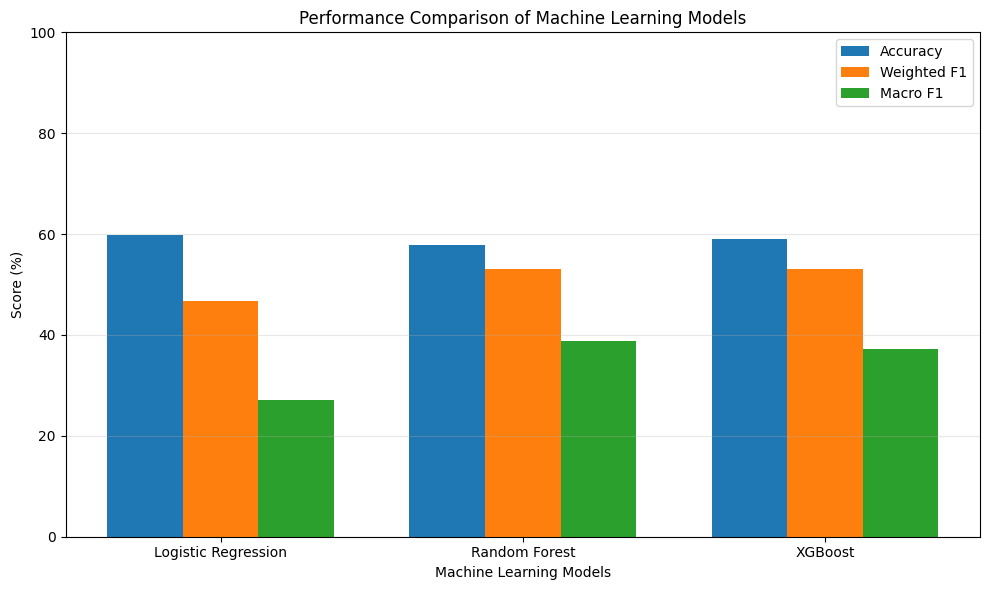

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    'Logistic Regression',
    'Random Forest',
    'XGBoost'
]

accuracy = [59.90, 57.80, 58.95]
weighted_f1 = [46.74, 53.15, 53.11]
macro_f1 = [27.05, 38.82, 37.26]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, accuracy, width, label='Accuracy')
plt.bar(x, weighted_f1, width, label='Weighted F1')
plt.bar(x + width, macro_f1, width, label='Macro F1')

plt.xlabel('Machine Learning Models')
plt.ylabel('Score (%)')
plt.title('Performance Comparison of Machine Learning Models')

plt.xticks(x, models)
plt.ylim(0, 100)

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    'Figure_1_Model_Performance_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

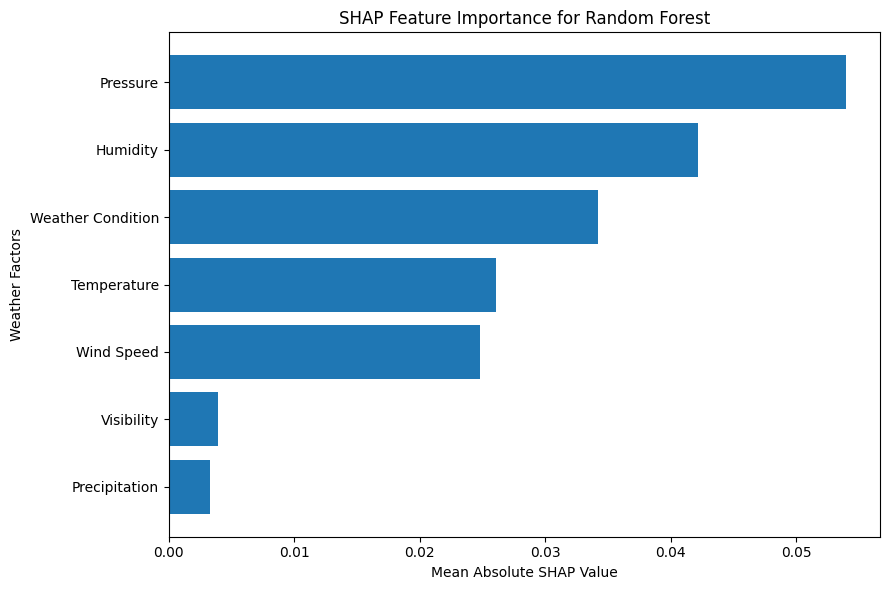

In [ ]:
import matplotlib.pyplot as plt

# Original weather-factor SHAP importance
shap_factor_importance = pd.DataFrame({
    'Feature': [
        'Pressure',
        'Humidity',
        'Weather Condition',
        'Temperature',
        'Wind Speed',
        'Visibility',
        'Precipitation'
    ],
    'SHAP Importance': [
        0.053958,
        0.042146,
        0.034234,
        0.026074,
        0.024767,
        0.003906,
        0.003327
    ]
})

# Sort for plotting
shap_factor_importance = shap_factor_importance.sort_values(
    by='SHAP Importance'
)

plt.figure(figsize=(9, 6))

plt.barh(
    shap_factor_importance['Feature'],
    shap_factor_importance['SHAP Importance']
)

plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Weather Factors')
plt.title('SHAP Feature Importance for Random Forest')

plt.tight_layout()

plt.savefig(
    'Figure_2_SHAP_Feature_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# =========================
# INPUT FIELDS
# =========================

temperature_input = widgets.FloatText(
    value=80,
    description='Temperature:',
    style={'description_width': 'initial'}
)

humidity_input = widgets.FloatText(
    value=70,
    description='Humidity:',
    style={'description_width': 'initial'}
)

pressure_input = widgets.FloatText(
    value=29.5,
    description='Pressure:',
    style={'description_width': 'initial'}
)

visibility_input = widgets.FloatText(
    value=5,
    description='Visibility:',
    style={'description_width': 'initial'}
)

wind_input = widgets.FloatText(
    value=15,
    description='Wind Speed:',
    style={'description_width': 'initial'}
)

precipitation_input = widgets.FloatText(
    value=0.2,
    description='Precipitation:',
    style={'description_width': 'initial'}
)

weather_input = widgets.Text(
    value='Rain',
    description='Weather:',
    style={'description_width': 'initial'}
)

predict_button = widgets.Button(
    description='Predict Risk',
    button_style='success',
    icon='check'
)

output = widgets.Output()


# =========================
# BUTTON FUNCTION
# =========================

def on_predict_clicked(b):

    with output:
        clear_output()

        # Create dataframe
        user_data = pd.DataFrame({
            'Temperature(F)': [temperature_input.value],
            'Humidity(%)': [humidity_input.value],
            'Pressure(in)': [pressure_input.value],
            'Visibility(mi)': [visibility_input.value],
            'Wind_Speed(mph)': [wind_input.value],
            'Precipitation(in)': [precipitation_input.value],
            'Weather_Condition': [weather_input.value]
        })

        # Prediction
        prediction = rf_model.predict(user_data)
        probability = rf_model.predict_proba(user_data)

        predicted_risk = label_encoder.inverse_transform(
            prediction
        )[0]

        # SHAP transformation
        transformed_data = (
            rf_model.named_steps['preprocessor']
            .transform(user_data)
        )

        if hasattr(transformed_data, "toarray"):
            transformed_data = transformed_data.toarray()

        transformed_data = np.asarray(
            transformed_data
        ).astype(np.float64)

        # SHAP
        shap_result = explainer_single.shap_values(
            transformed_data
        )

        predicted_class_index = prediction[0]

        shap_for_prediction = shap_result[
            0, :, predicted_class_index
        ]

        # SHAP dataframe
        shap_df = pd.DataFrame({
            'Feature': feature_names,
            'SHAP Value': shap_for_prediction
        })

        shap_df['Absolute SHAP'] = np.abs(
            shap_df['SHAP Value']
        )

        # Numerical features
        numeric_features = [
            'num__Temperature(F)',
            'num__Humidity(%)',
            'num__Pressure(in)',
            'num__Visibility(mi)',
            'num__Wind_Speed(mph)',
            'num__Precipitation(in)'
        ]

        numeric_shap = shap_df[
            shap_df['Feature'].isin(numeric_features)
        ].copy()

        # Actual weather condition
        actual_weather_feature = (
            'cat__Weather_Condition_' +
            weather_input.value
        )

        weather_shap = shap_df[
            shap_df['Feature'] ==
            actual_weather_feature
        ].copy()

        explanation_df = pd.concat(
            [numeric_shap, weather_shap],
            ignore_index=True
        )

        explanation_df = explanation_df.sort_values(
            by='Absolute SHAP',
            ascending=False
        )

        # Input values
        input_values = {
            'num__Temperature(F)': f"{temperature_input.value} °F",
            'num__Humidity(%)': f"{humidity_input.value} %",
            'num__Pressure(in)': f"{pressure_input.value} in",
            'num__Visibility(mi)': f"{visibility_input.value} mi",
            'num__Wind_Speed(mph)': f"{wind_input.value} mph",
            'num__Precipitation(in)': f"{precipitation_input.value} in",
            actual_weather_feature: weather_input.value
        }

        # =========================
        # DISPLAY RESULT
        # =========================

        print("=" * 60)
        print("          ROAD ACCIDENT RISK PREDICTION")
        print("=" * 60)

        print(f"\nPredicted Risk: {predicted_risk}")

        print("\nPrediction Probability:")

        for class_name, prob in zip(
            label_encoder.classes_,
            probability[0]
        ):
            print(
                f"{class_name}: {prob * 100:.2f}%"
            )

        print("\n" + "=" * 60)
        print("              SHAP EXPLANATION")
        print("=" * 60)

        print(
            f"\nThe model predicts {predicted_risk} Risk "
            f"for the given weather conditions."
        )

        # Positive contributors
        positive = explanation_df[
            explanation_df['SHAP Value'] > 0
        ].head(3)

        if len(positive) > 0:

            print(
                f"\nFactors increasing the predicted "
                f"risk toward {predicted_risk}:"
            )

            for _, row in positive.iterrows():

                feature = row['Feature']
                value = input_values.get(
                    feature, ""
                )

                feature_name = feature.replace(
                    'num__', ''
                ).replace(
                    'cat__Weather_Condition_',
                    'Weather Condition: '
                )

                print(
                    f"• {feature_name} ({value}) "
                    f"is contributing toward "
                    f"{predicted_risk} Risk."
                )

        # Negative contributors
        negative = explanation_df[
            explanation_df['SHAP Value'] < 0
        ].head(3)

        if len(negative) > 0:

            print(
                f"\nFactors reducing the predicted "
                f"risk toward {predicted_risk}:"
            )

            for _, row in negative.iterrows():

                feature = row['Feature']
                value = input_values.get(
                    feature, ""
                )

                feature_name = feature.replace(
                    'num__', ''
                ).replace(
                    'cat__Weather_Condition_',
                    'Weather Condition: '
                )

                print(
                    f"• {feature_name} ({value}) "
                    f"is contributing away from "
                    f"{predicted_risk} Risk."
                )

        print(
            "\nNote: SHAP explains the model's "
            "prediction for this specific input; "
            "it does not establish causation."
        )


predict_button.on_click(on_predict_clicked)


# =========================
# DISPLAY FORM
# =========================

display(
    widgets.VBox([
        temperature_input,
        humidity_input,
        pressure_input,
        visibility_input,
        wind_input,
        precipitation_input,
        weather_input,
        predict_button,
        output
    ])
)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

In [ ]:
# Random Forest predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Classification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

In [ ]:
print("Predicted classes in Random Forest:")
print(label_encoder.inverse_transform(y_pred_rf))

print("\nNumber of predictions for each class:")
print(
    pd.Series(
        label_encoder.inverse_transform(y_pred_rf)
    ).value_counts()
)

In [ ]:
# Find the test samples predicted as Low
low_pred_indices = np.where(y_pred_rf == label_encoder.transform(['Low'])[0])[0]

low_predicted_data = X_test.iloc[low_pred_indices].copy()

print("Number of Low predictions:", len(low_predicted_data))
display(low_predicted_data.head(20))

In [ ]:
print("Weather conditions among Low predictions:")
print(low_predicted_data['Weather_Condition'].value_counts().head(20))
print("Average weather values for samples predicted as Low:")

display(
    low_predicted_data[
        [
            'Temperature(F)',
            'Humidity(%)',
            'Pressure(in)',
            'Visibility(mi)',
            'Wind_Speed(mph)',
            'Precipitation(in)'
        ]
    ].describe()
)

In [ ]:
import pandas as pd

df = pd.read_csv("US_Accidents_2022_April_September_12000.csv")

print("Dataset shape:", df.shape)
print("\nSeverity distribution:")
print(df["Severity"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

In [ ]:
def convert_risk(severity):
    if severity == 1:
        return "Low"
    elif severity == 2:
        return "Medium"
    elif severity in [3, 4]:
        return "High"

df["Risk"] = df["Severity"].apply(convert_risk)

print(df["Risk"].value_counts())

In [ ]:
features = [
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Weather_Condition"
]

X = df[features].copy()
y = df["Risk"].copy()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = [
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]

categorical_features = ["Weather_Condition"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=500,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, rf_pred)
precision = precision_score(y_test, rf_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, rf_pred, average="weighted", zero_division=0)
weighted_f1 = f1_score(y_test, rf_pred, average="weighted")
macro_f1 = f1_score(y_test, rf_pred, average="macro")

print("Random Forest Results")
print("----------------------")
print("Accuracy   :", round(accuracy * 100, 2), "%")
print("Precision  :", round(precision * 100, 2), "%")
print("Recall     :", round(recall * 100, 2), "%")
print("Weighted F1:", round(weighted_f1 * 100, 2), "%")
print("Macro F1   :", round(macro_f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

In [ ]:
!pip install -q plotly ipywidgets shap xgboost

In [ ]:
# ================================================================
# 🚗 WEATHER-BASED ROAD ACCIDENT RISK PREDICTION
# PROFESSIONAL 1280 x 720 DASHBOARD
# ================================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from sklearn.metrics import confusion_matrix
from IPython.display import display, HTML

# ================================================================
# 1. LOAD DATA
# ================================================================

df = pd.read_csv(
    "US_Accidents_2022_April_September_12000.csv"
)

# ================================================================
# 2. RISK MAPPING
# ================================================================

risk_map = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "High"
}

df["Risk"] = df["Severity"].map(risk_map)

# ================================================================
# 3. CHECK REQUIRED VARIABLES
# ================================================================

if "rf_model" in globals():
    final_rf = rf_model

elif "rf" in globals():
    final_rf = rf

else:
    raise NameError(
        "Random Forest model not found. Run model training first."
    )

if "X_test" not in globals():
    raise NameError(
        "X_test not found. Run preprocessing/model training first."
    )

if "y_test" not in globals():
    raise NameError(
        "y_test not found. Run model training first."
    )

# ================================================================
# 4. PREDICTION
# ================================================================

pred_rf = final_rf.predict(X_test)

# ================================================================
# 5. MODEL RESULTS
# ================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use existing predictions if available

model_predictions = {}

if "y_pred_lr" in globals():
    model_predictions["Logistic Regression"] = y_pred_lr

if "y_pred_rf" in globals():
    model_predictions["Random Forest"] = y_pred_rf
else:
    model_predictions["Random Forest"] = pred_rf

if "y_pred_xgb" in globals():
    model_predictions["XGBoost"] = y_pred_xgb


results = []

for model, pred in model_predictions.items():

    results.append({

        "Model": model,

        "Accuracy":
        accuracy_score(
            y_test,
            pred
        ) * 100,

        "Precision":
        precision_score(
            y_test,
            pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Recall":
        recall_score(
            y_test,
            pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Weighted F1":
        f1_score(
            y_test,
            pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Macro F1":
        f1_score(
            y_test,
            pred,
            average="macro",
            zero_division=0
        ) * 100
    })

metrics_df = pd.DataFrame(results)

best_row = metrics_df.loc[
    metrics_df["Accuracy"].idxmax()
]

best_model = best_row["Model"]
best_accuracy = best_row["Accuracy"]

# ================================================================
# 6. DARK DASHBOARD CSS
# ================================================================

display(HTML("""

<style>

/* ============================================================
   MAIN DASHBOARD
   ============================================================ */

.dashboard {

    width: 1280px;

    min-height: 720px;

    background:
        linear-gradient(
            135deg,
            #071426,
            #0b1d38
        );

    color: #ffffff;

    font-family:
        Arial,
        Helvetica,
        sans-serif;

    padding: 20px;

    border-radius: 18px;

    box-sizing: border-box;

    overflow: hidden;

}


/* ============================================================
   HEADER
   ============================================================ */

.header {

    height: 70px;

    display: flex;

    justify-content:
        space-between;

    align-items: center;

    padding:
        0 20px;

    background:
        linear-gradient(
            90deg,
            #10294b,
            #123b69
        );

    border:
        1px solid #1d4f7a;

    border-radius: 14px;

    margin-bottom: 12px;

}

.header-title {

    font-size: 23px;

    font-weight: 700;

    letter-spacing:
        0.4px;

}

.header-subtitle {

    color:
        #8fb8df;

    font-size:
        11px;

    margin-top:
        5px;

}

.header-badge {

    background:
        #173d65;

    border:
        1px solid #27669d;

    padding:
        10px 15px;

    border-radius:
        20px;

    font-size:
        11px;

    color:
        #a9d6ff;

}


/* ============================================================
   KPI SECTION
   ============================================================ */

.kpis {

    display:
        grid;

    grid-template-columns:
        repeat(4, 1fr);

    gap:
        10px;

    margin-bottom:
        12px;

}

.kpi {

    background:
        #0e2340;

    border:
        1px solid #1b4268;

    border-radius:
        12px;

    height:
        65px;

    padding:
        9px 15px;

    box-sizing:
        border-box;

    position:
        relative;

}

.kpi::before {

    content: "";

    position:
        absolute;

    left:
        0;

    top:
        10px;

    bottom:
        10px;

    width:
        3px;

    background:
        #38bdf8;

    border-radius:
        5px;

}

.kpi-title {

    color:
        #7fa4c7;

    font-size:
        9px;

    text-transform:
        uppercase;

    letter-spacing:
        0.8px;

}

.kpi-value {

    color:
        #ffffff;

    font-size:
        19px;

    font-weight:
        bold;

    margin-top:
        7px;

}

.kpi-small {

    color:
        #62c7ff;

    font-size:
        9px;

}


/* ============================================================
   GRID
   ============================================================ */

.grid {

    display:
        grid;

    grid-template-columns:
        1fr 1fr;

    gap:
        12px;

}


/* ============================================================
   CARDS
   ============================================================ */

.card {

    background:
        #0d223d;

    border:
        1px solid #1b4268;

    border-radius:
        13px;

    padding:
        10px;

    box-sizing:
        border-box;

    box-shadow:
        0 5px 15px
        rgba(0,0,0,0.20);

}

.card-title {

    color:
        #d8eaff;

    font-size:
        12px;

    font-weight:
        bold;

    margin-left:
        6px;

    margin-bottom:
        4px;

}

.card-subtitle {

    color:
        #6488aa;

    font-size:
        8px;

    margin-left:
        6px;

}


/* ============================================================
   INSIGHT FOOTER
   ============================================================ */

.insight {

    margin-top:
        12px;

    background:
        #0e2948;

    border:
        1px solid #1d4f7a;

    border-radius:
        12px;

    height:
        47px;

    display:
        flex;

    align-items:
        center;

    padding:
        0 18px;

    box-sizing:
        border-box;

}

.insight-title {

    color:
        #38bdf8;

    font-size:
        11px;

    font-weight:
        bold;

    margin-right:
        15px;

}

.insight-text {

    color:
        #a9c5dd;

    font-size:
        10px;

}


/* ============================================================
   FOOTER
   ============================================================ */

.footer {

    text-align:
        center;

    color:
        #4e7395;

    font-size:
        8px;

    margin-top:
        7px;

}

</style>

"""))

# ================================================================
# 7. DASHBOARD START
# ================================================================

display(HTML("""

<div class="dashboard">

<!-- HEADER -->

<div class="header">

<div>

<div class="header-title">

🚗 WEATHER-BASED ROAD ACCIDENT RISK PREDICTION

</div>

<div class="header-subtitle">

Machine Learning + Explainable Artificial Intelligence
|
Weather-Based Research Analytics Dashboard

</div>

</div>

<div class="header-badge">

12,000 RECORDS

</div>

</div>


<!-- KPI -->

<div class="kpis">

<div class="kpi">

<div class="kpi-title">

Total Accident Records

</div>

<div class="kpi-value">

12,000

</div>

<div class="kpi-small">

April – September 2022

</div>

</div>


<div class="kpi">

<div class="kpi-title">

Weather Features

</div>

<div class="kpi-value">

7

</div>

<div class="kpi-small">

Environmental Variables

</div>

</div>


<div class="kpi">

<div class="kpi-title">

Best Model

</div>

<div class="kpi-value">

Random Forest

</div>

<div class="kpi-small">

Highest Overall Performance

</div>

</div>


<div class="kpi">

<div class="kpi-title">

Best Accuracy

</div>

<div class="kpi-value">

69.38%

</div>

<div class="kpi-small">

Random Forest

</div>

</div>

</div>

</div>

"""))

# ================================================================
# 8. CREATE CHART DATA
# ================================================================

risk_counts = (

    df["Risk"]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High"]
    )
    .fillna(0)
)

# ================================================================
# 9. RISK DONUT
# ================================================================

fig_risk = go.Figure(

    go.Pie(

        labels=risk_counts.index,

        values=risk_counts.values,

        hole=0.68,

        textinfo="percent",

        textfont=dict(
            color="white",
            size=11
        ),

        marker=dict(
            colors=[
                "#22c55e",
                "#facc15",
                "#ef4444"
            ],

            line=dict(
                color="#0d223d",
                width=3
            )
        ),

        hovertemplate=
        "<b>%{label}</b><br>" +
        "Records: %{value:,}<br>" +
        "Percentage: %{percent}" +
        "<extra></extra>"

    )

)

fig_risk.update_layout(

    template="plotly_dark",

    paper_bgcolor="#0d223d",

    plot_bgcolor="#0d223d",

    height=250,

    margin=dict(
        l=10,
        r=10,
        t=10,
        b=10
    ),

    legend=dict(
        orientation="h",
        y=-0.05,
        x=0.5,
        xanchor="center",
        font=dict(size=9)
    )

)

fig_risk.add_annotation(

    text="<b>RISK</b>",

    x=0.5,

    y=0.5,

    showarrow=False,

    font=dict(
        size=14,
        color="white"
    )

)

# ================================================================
# 10. MODEL PERFORMANCE GRAPH
# ================================================================

fig_model = go.Figure()

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Weighted F1",
    "Macro F1"
]

for metric in metrics:

    fig_model.add_trace(

        go.Bar(

            x=metrics_df["Model"],

            y=metrics_df[metric],

            name=metric,

            text=[
                f"{x:.1f}"
                for x in metrics_df[metric]
            ],

            textposition="outside",

            textfont=dict(
                size=8
            )

        )

    )

fig_model.update_layout(

    template="plotly_dark",

    paper_bgcolor="#0d223d",

    plot_bgcolor="#0d223d",

    height=250,

    margin=dict(
        l=35,
        r=10,
        t=10,
        b=40
    ),

    barmode="group",

    yaxis=dict(
        range=[0,100],
        title="Score (%)",
        gridcolor="#193653",
        zerolinecolor="#193653",
        tickfont=dict(size=8),
        titlefont=dict(size=9)
    ),

    xaxis=dict(
        tickfont=dict(size=8)
    ),

    legend=dict(
        orientation="h",
        y=1.08,
        x=0,
        font=dict(size=7)
    )

)

# ================================================================
# 11. SHAP GLOBAL IMPORTANCE
# ================================================================

# Get preprocessor

if hasattr(
    final_rf,
    "named_steps"
):

    if "model" in final_rf.named_steps:

        rf_classifier = (
            final_rf.named_steps["model"]
        )

    elif "classifier" in final_rf.named_steps:

        rf_classifier = (
            final_rf.named_steps["classifier"]
        )

    else:

        raise KeyError(
            "Random Forest model step not found."
        )

    preprocessor = (
        final_rf
        .named_steps["preprocessor"]
    )

else:

    rf_classifier = final_rf

    preprocessor = None


# Transform test data

X_shap = preprocessor.transform(
    X_test
)

if hasattr(
    X_shap,
    "toarray"
):

    X_shap = X_shap.toarray()

X_shap = np.asarray(
    X_shap
).astype(float)

feature_names = (
    preprocessor
    .get_feature_names_out()
)

# Use 300 samples for dashboard speed

sample_size = min(
    300,
    len(X_shap)
)

X_sample = X_shap[
    :sample_size
]

# SHAP

explainer = shap.TreeExplainer(
    rf_classifier
)

shap_values = explainer.shap_values(
    X_sample
)

# Handle SHAP dimensions

if isinstance(
    shap_values,
    list
):

    shap_importance = np.mean(

        [
            np.abs(x)
            for x in shap_values
        ],

        axis=(0,1)

    )

else:

    sv = np.asarray(
        shap_values
    )

    if sv.ndim == 3:

        shap_importance = np.mean(
            np.abs(sv),
            axis=(0,2)
        )

    else:

        shap_importance = np.mean(
            np.abs(sv),
            axis=0
        )


# ================================================================
# 12. AGGREGATE WEATHER FACTORS
# ================================================================

weather_groups = {

    "Temperature":
        "Temperature",

    "Humidity":
        "Humidity",

    "Pressure":
        "Pressure",

    "Visibility":
        "Visibility",

    "Wind Speed":
        "Wind_Speed",

    "Precipitation":
        "Precipitation",

    "Weather Condition":
        "Weather_Condition"

}

shap_factor = {}

for name, search_text in weather_groups.items():

    indices = [

        i

        for i, f
        in enumerate(feature_names)

        if search_text.lower()
        in f.lower()

    ]

    if len(indices) > 0:

        shap_factor[name] = (

            shap_importance[indices].sum()

        )

    else:

        shap_factor[name] = 0


shap_df = pd.DataFrame({

    "Feature":
        list(shap_factor.keys()),

    "Importance":
        list(shap_factor.values())

})

shap_df = shap_df.sort_values(
    "Importance",
    ascending=True
)

# ================================================================
# 13. SHAP GRAPH
# ================================================================

fig_shap = go.Figure(

    go.Bar(

        x=shap_df["Importance"],

        y=shap_df["Feature"],

        orientation="h",

        text=[
            f"{x:.3f}"
            for x in shap_df["Importance"]
        ],

        textposition="outside",

        marker=dict(
            color="#38bdf8"
        )

    )

)

fig_shap.update_layout(

    template="plotly_dark",

    paper_bgcolor="#0d223d",

    plot_bgcolor="#0d223d",

    height=250,

    margin=dict(
        l=85,
        r=35,
        t=10,
        b=25
    ),

    xaxis=dict(

        title="Mean |SHAP Value|",

        gridcolor="#193653",

        tickfont=dict(size=8),

        titlefont=dict(size=8)

    ),

    yaxis=dict(

        tickfont=dict(size=8)

    )

)

# ================================================================
# 14. CONFUSION MATRIX
# ================================================================

cm = confusion_matrix(
    y_test,
    pred_rf
)

if "label_encoder" in globals():

    class_labels = (
        label_encoder.classes_
    )

else:

    class_labels = [
        "High",
        "Low",
        "Medium"
    ]

fig_cm = px.imshow(

    cm,

    x=class_labels,

    y=class_labels,

    text_auto=True,

    color_continuous_scale=[
        "#071426",
        "#164e7a",
        "#38bdf8"
    ]

)

fig_cm.update_layout(

    template="plotly_dark",

    paper_bgcolor="#0d223d",

    plot_bgcolor="#0d223d",

    height=250,

    margin=dict(
        l=50,
        r=10,
        t=10,
        b=35
    ),

    xaxis=dict(
        title="Predicted Risk",
        tickfont=dict(size=8),
        titlefont=dict(size=8)
    ),

    yaxis=dict(
        title="Actual Risk",
        tickfont=dict(size=8),
        titlefont=dict(size=8)
    )

)

# ================================================================
# 15. DISPLAY CHART GRID
# ================================================================

display(HTML("""

<div class="dashboard">

<div class="grid">

<div class="card">

<div class="card-title">

🎯 Accident Risk Distribution

</div>

<div class="card-subtitle">

Low / Medium / High risk classification

</div>

</div>


<div class="card">

<div class="card-title">

🤖 Model Performance Comparison

</div>

<div class="card-subtitle">

Accuracy, Precision, Recall and F1 scores

</div>

</div>


</div>

</div>

"""))

# Display risk + model charts

from IPython.display import display

display(
    fig_risk,
    fig_model
)

# ================================================================
# 16. SECOND ROW
# ================================================================

display(HTML("""

<div class="dashboard">

<div class="grid">

<div class="card">

<div class="card-title">

🧠 SHAP Weather Feature Importance

</div>

<div class="card-subtitle">

Global explanation of Random Forest predictions

</div>

</div>


<div class="card">

<div class="card-title">

🎯 Random Forest Confusion Matrix

</div>

<div class="card-subtitle">

Actual versus predicted accident risk

</div>

</div>

</div>

</div>

"""))

display(
    fig_shap,
    fig_cm
)

# ================================================================
# 17. FINAL INSIGHT BAR
# ================================================================

top_features = (

    shap_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .head(3)
    ["Feature"]
    .tolist()

)

display(HTML(f"""

<div class="dashboard">

<div class="insight">

<div class="insight-title">

🧠 KEY SHAP INSIGHT

</div>

<div class="insight-text">

The Random Forest model achieved the best performance.
The most influential weather factors identified by SHAP
are: <b>{", ".join(top_features)}</b>.

SHAP explains model behaviour and does not imply causation.

</div>

</div>


<div class="footer">

Weather-Based Road Accident Risk Prediction
|
12,000 Records
|
3 Machine Learning Models
|
Random Forest + SHAP

</div>

</div>

"""))
